# 03 · Escenarios y simulación de A013: ¿cuántos coches fabricamos?

**Preguntas 3, 4 y 5 del caso:**
- **3.** ¿Qué pasa si el año sale mejor o peor? → escenarios central, optimista y pesimista.
- **4.** ¿Cuántos coches fabricamos y cuánto stock queremos? → plan mensual por segmento.
- **5.** ¿Cuánto cuesta equivocarse y qué recomendamos?

### Flujo de la simulación
```
Escenario → demanda esperada → plan (con la previsión central) → simular 1.000 años con demanda al azar → Tabla 5
```
Cada mes simulado: se vende lo que se puede, lo que falta es transfer o venta perdida, se revisa la previsión con lo observado y se decide la llegada de **t+3** con
```
pedido(t+3) = máx(0, demanda prevista(t+3) + colchón − stock previsto al empezar t+3)
```

### Índice
1. Previsión central de A013
2. Los tres escenarios
3. Situación de partida: stock y coches en camino
4. La política de pedidos: colchón por segmento (problema del *newsvendor*)
5. El plan de fabricación propuesto
6. Simulación: la Tabla 5
7. ¿Cuánto cuesta equivocarse? Sensibilidad del colchón
8. Conclusiones y recomendaciones

In [1]:
import sys, warnings
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datos import cargar, panel_segmento, macro, SEGMENTOS
from demanda import (exogenas, meses_evento, ajustar_mercado, prever_mercado, peso_segmento,
                     cuota_media)
from simulacion import (prevision_a013, economia_coche, z_por_segmento, situacion_inicial,
                        simular, plan_central, tabla5, ESCENARIOS, MESES, NOMBRES_MES)
from graficos import (estilo, es, eje_miles, eje_fechas, anio_caso, guardar,
                      COLORES, NOMBRES, AZUL, ROJO, TINTA, TINTA_2, APAGADO, BANDA)

estilo()
d = cargar()
p = panel_segmento(d)
mac = macro(d)
COLOR_ESC = {"Pesimista": "#e34948", "Central": "#2a78d6", "Optimista": "#1baf7a"}
ORDEN_ESC = ["Pesimista", "Central", "Optimista"]
millones = lambda x: es(x / 1e6, 1) + " M€"

## 1. Previsión central de A013

Reentrenamos el modelo del notebook 02 con **todos los datos hasta A012** (los meses de adelanto, como siempre, como dato que falta) y prevemos los 12 meses de A013.

**Supuestos del escenario central** (Tabla 4: *"como al final de A012"*):
- Paro y confianza del consumidor **congelados** en su valor de diciembre de A012.
- Sin planes de ayuda ni subidas del IVA.
- **Caída tras el adelanto durante 3 meses.** Los coches que se adelantaron en nov–dic A012 se "devuelven" en ene–mar A013.
- Peso de los segmentos con su tendencia; cuota = media de los últimos 12 meses (sin diciembre en los segmentos que se quedaron sin coches). **SUV compacto: 2,7 %**, su última cuota observada.

In [2]:
prev, info = prevision_a013(d, p, mac)
mercado = p["mercado"].unstack("segmento").asfreq("MS")[SEGMENTOS]
demanda = p["demanda"].unstack("segmento").asfreq("MS")[SEGMENTOS]
total = mercado.sum(axis=1)

print(f"Coches adelantados en nov-dic A012 (mercado): {es(info['adelantados'])}")
print(f"-> caída del {es(100 * info['hondura'], 1)} % al mes durante la caída tras el adelanto")
print(f"Confianza del consumidor: {es(mac.loc['2012-01-01', 'confianza_consumidor'], 1)} (ene A012) -> "
      f"{es(mac.loc['2012-12-01', 'confianza_consumidor'], 1)} (dic A012)")

resumen = pd.DataFrame({
    "Mercado A012 (real)": [total.loc["2012"].sum()] + [np.nan] * 7,
}, index=["Mercado total"] + [f"Kaido {s} · {NOMBRES[s]}" for s in SEGMENTOS])
resumen["Real A012"] = [total.loc["2012"].sum()] + list(demanda.loc["2012"].sum())
resumen["Previsto A013 (central)"] = [info["mercado"]["Central"].sum()] + list(prev["Central"].sum())
resumen["Variación (%)"] = 100 * (resumen["Previsto A013 (central)"] / resumen["Real A012"] - 1)
resumen = resumen.drop(columns="Mercado A012 (real)")
resumen.style.format({"Real A012": es, "Previsto A013 (central)": es, "Variación (%)": lambda x: es(x, 1)})

Coches adelantados en nov-dic A012 (mercado): 15.102
-> caída del 7,5 % al mes durante la caída tras el adelanto
Confianza del consumidor: 93,8 (ene A012) -> 77,7 (dic A012)


,Real A012,Previsto A013 (central),Variación (%)
Mercado total,902.437,774.731,"-14,2"
Kaido MSUV · SUV medio,7.481,7.155,"-4,4"
Kaido SSUV · SUV pequeño,5.635,6.363,"12,9"
Kaido C · Compacto,3.696,2.800,"-24,2"
Kaido B · Pequeño,1.623,1.278,"-21,3"
Kaido CSUV · SUV compacto,1.192,4.387,"268,0"
Kaido MD · Berlina media,591,370,"-37,4"
Kaido S · Descapotable,488,376,"-22,9"


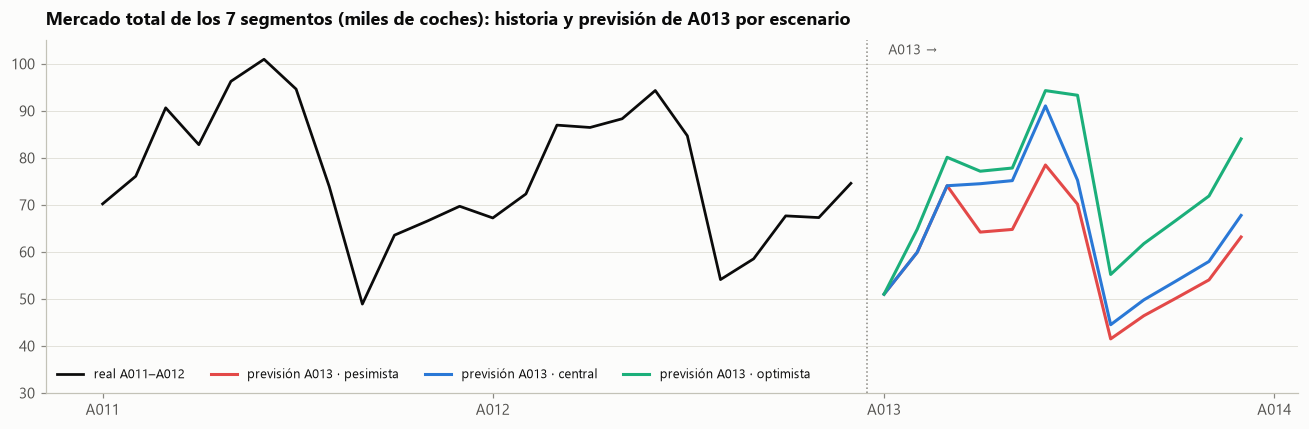

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
hist = total["2011-01":"2012-12"]
ax.plot(hist.index, hist / 1000, color=TINTA, lw=1.8, label="real A011–A012")
for e in ORDEN_ESC:
    ax.plot(MESES, info["mercado"][e] / 1000, color=COLOR_ESC[e], lw=2, label=f"previsión A013 · {e.lower()}")
ax.axvline(pd.Timestamp("2012-12-16"), color=APAGADO, lw=1, ls=":")
ax.text(pd.Timestamp("2013-01-05"), 102, "A013 →", color=TINTA_2, fontsize=9)
eje_fechas(ax)
ax.set_ylim(30, 105)
ax.set_title("Mercado total de los 7 segmentos (miles de coches): historia y previsión de A013 por escenario")
ax.legend(loc="lower left", ncols=4, fontsize=8.5)
fig.tight_layout()
guardar(fig, "20_prevision_mercado_A013")

**Resultados.**
- **El mercado cae ≈14 % en A013** en el escenario central (de 902.000 a ≈775.000). Dos razones:
  1. **La confianza del consumidor se hundió** en la segunda mitad de A012 (de 94 a 78 puntos). Con 3 meses de retraso, eso llega al mercado en A013: −16 puntos × 0,9 % ≈ −14 %.
  2. **La caída tras el adelanto**: los ≈15.000 coches adelantados se restan en ene–mar.
- **Kaido aguanta mejor que el mercado** gracias al **SUV compacto**, que vende un año entero (≈4.400 coches frente a 1.192 en 5 meses), y al peso creciente de los SUV.
- **La gama de siempre baja**: compacto −24 %, pequeño −21 %, berlina −37 %.

> **Mensaje para el comité:** A013 no es un año para crecer. Planificar con el ritmo de A012 llenaría la red de coches otra vez.

## 2. Los tres escenarios

Traducimos la Tabla 4 a cambios concretos en el modelo. Cada suceso entra por su sitio:

| Suceso | Pesimista | Central | Optimista | Entra por |
|---|---|---|---|---|
| **Economía** | Paro **+2 puntos** (≈ −7 % de mercado desde abril) | Como a final de A012 | Paro **−1 punto** (≈ +3,5 %) | Mercado (SARIMAX) |
| **Normativa** | Caída tras el adelanto **6 meses** + **prima de CO₂** | Caída **3 meses** | Caída **1 mes** + **plan de ayuda desde julio** (≈ +20 %) | Mercado / beneficio por coche |
| **Producto** | Lanzamiento retrasado: cuota **−15 % en ene–mar** en los segmentos con códigos nuevos | A tiempo | Códigos nuevos venden mejor: cuota **+10 %** todo el año | Cuota |
| **Geopolítica** | Arancel: coste de fabricar **+3 %** | Sin cambios | Euro fuerte: coste **−2 %** | Beneficio por coche |
| **Suministro** | La fábrica pierde **junio del SUV medio** | Sin problemas | Coches de sobra | Llegadas |
| **Turismo** | Menos alquiladores | Como A012 | Más alquiladores | *Fuera: los alquiladores son el 2 % de Kaido* |

Dimensionados con episodios reales de los datos: el adelanto de A011 tuvo una caída de 4 meses; los planes de ayuda de A005–A008 subieron el mercado ≈20 %; el coeficiente del paro sale del modelo.

**Importante:** el plan se hace **siempre con la previsión central**. En los otros escenarios la demanda real es distinta y el plan solo se puede corregir a 3 meses vista.

In [4]:
dem_esc = pd.DataFrame({e: prev[e].sum() for e in ORDEN_ESC})
dem_esc.index = [f"{s} · {NOMBRES[s]}" for s in dem_esc.index]
dem_esc.loc["TOTAL"] = dem_esc.sum()
dem_esc.loc["Mercado total"] = info["mercado"][ORDEN_ESC].sum()
dem_esc.style.format(es).set_caption("Demanda esperada de A013 por escenario (coches)")

,Pesimista,Central,Optimista
MSUV · SUV medio,6.374,7.155,8.921
SSUV · SUV pequeño,5.668,6.363,7.933
C · Compacto,2.594,2.800,3.173
B · Pequeño,1.138,1.278,1.593
CSUV · SUV compacto,3.908,4.387,5.469
MD · Berlina media,343,370,419
S · Descapotable,349,376,427
TOTAL,20.374,22.729,27.935
Mercado total,717.861,774.731,878.058


## 3. Situación de partida: stock y coches en camino

- **Stock a 31 de diciembre de A012**: dato real, por segmento y antigüedad.
- **Coches en camino para enero y febrero**: no tenemos el dato. **Supuesto:** igual al *wholesale* medio de oct–dic A012 de cada segmento (lo que se estaba facturando a la red al final del año).

In [5]:
stock0, en_camino = situacion_inicial(d)
st = d["stock_mensual"]
dic = st[(st.anio == "A012") & (st.mes == 12)].set_index("segmento").loc[SEGMENTOS]
partida = pd.DataFrame({
    "Stock 31-dic": dic["stock_total"],
    "  de ellos >90 días": dic["s_91_180"] + dic["s_mas_180"],
    "En camino ene (supuesto)": en_camino,
    "En camino feb (supuesto)": en_camino,
    "Demanda prevista ene+feb": prev["Central"].iloc[:2].sum().to_numpy(),
}, index=SEGMENTOS)
partida["Stock previsto fin feb"] = (partida["Stock 31-dic"] + partida["En camino ene (supuesto)"]
                                    + partida["En camino feb (supuesto)"] - partida["Demanda prevista ene+feb"])
partida.index = [f"{s} · {NOMBRES[s]}" for s in partida.index]
partida.loc["TOTAL"] = partida.sum()
partida.style.format(es)

,Stock 31-dic,de ellos >90 días,En camino ene (supuesto),En camino feb (supuesto),Demanda prevista ene+feb,Stock previsto fin feb
MSUV · SUV medio,536,101,681,681,1.024,874
SSUV · SUV pequeño,0,0,249,249,911,-413
C · Compacto,1.107,479,491,491,401,1.688
B · Pequeño,97,0,90,90,183,94
CSUV · SUV compacto,1.011,327,525,525,628,1.433
MD · Berlina media,125,108,21,21,53,114
S · Descapotable,1,1,31,31,54,9
TOTAL,2.877,1.016,2.088,2.088,3.254,3.799


**Resultados.** el punto de partida está **desequilibrado**:
- **Compacto (C):** llegará a marzo con ≈1.700 coches de sobra (más de 6 meses de venta). → **Su producción se parará varios meses.**
- **SUV pequeño (SSUV):** empieza con **0 coches** y llega poco → en enero–febrero faltarán coches (transfers) y el pedido de marzo será enorme.
- **SUV compacto:** llega con mucho stock del lanzamiento → producción baja al principio.

Es justo lo que avisaba el enunciado con la Tabla 3: *"si lo que viene en camino es mucho, el ajuste lo sufre el primer mes que todavía se puede tocar"*.

## 4. La política de pedidos: un colchón distinto para cada segmento

### El problema del vendedor de periódicos (*newsvendor*)
Un clásico de la investigación operativa (y de las finanzas: es la misma lógica que fijar un nivel de cobertura de riesgo). Un quiosquero decide cuántos periódicos comprar sin saber cuántos venderá:
- **Cu** = lo que cuesta quedarse **corto** un ejemplar.
- **Co** = lo que cuesta que **sobre** un ejemplar.

La cantidad óptima cubre la demanda con probabilidad
```
ratio crítico = Cu / (Cu + Co)        →        z = Φ⁻¹(ratio crítico)
```
(Φ⁻¹ es la inversa de la normal: ratio 0,90 → z = 1,28; ratio 0,95 → z = 1,65, los dos valores que da el enunciado.)

**En Kaido, por segmento:**
- **Cu:** si el transfer deja dinero → lo que cuesta el transfer (20 % del beneficio bruto). Si no → el CVP que se pierde.
- **Co:** un coche que sobra ≈ 3 meses → 3 × 60 € de stock + el VM extra por pasar de 90 días.

En vez de poner z = 1,28 a todos, **cada segmento tiene el suyo** (el enunciado: *"el stock de seguridad no tiene por qué ser igual en todos"*).

In [6]:
econ = economia_coche(d["segmentos"])
zs = z_por_segmento(econ)
t = zs.join(econ[["bb", "cvp_transfer"]])
t.index = [f"{s} · {NOMBRES[s]}" for s in t.index]
t = t[["bb", "cvp_transfer", "Cu", "Co", "ratio_critico", "z"]]
t.columns = ["Beneficio bruto (€)", "CVP de un transfer (€)", "Cu: quedarse corto (€)",
             "Co: pasarse (€)", "Ratio crítico", "z"]
t.style.format(es).format(lambda x: es(x, 2), subset=["Ratio crítico", "z"])

,Beneficio bruto (€),CVP de un transfer (€),Cu: quedarse corto (€),Co: pasarse (€),Ratio crítico,z
MSUV · SUV medio,7.782,4.331,1.556,375,"0,81","0,86"
SSUV · SUV pequeño,4.833,1.890,967,228,"0,81","0,87"
C · Compacto,3.672,633,734,447,"0,62","0,31"
B · Pequeño,1.842,-243,125,208,"0,38","0,00"
CSUV · SUV compacto,6.174,2.569,1.235,280,"0,82","0,90"
MD · Berlina media,7.561,2.532,1.512,364,"0,81","0,86"
S · Descapotable,6.841,3.586,1.368,436,"0,76","0,70"


**Resultados.**
- En casi todos los segmentos quedarse corto cuesta **3–5 veces más** que pasarse → ratio ≈ 0,8 → z ≈ 0,9.
- **Compacto:** el VM sube mucho cuando el coche envejece → pasarse es caro → z bajo (0,3).
- **Pequeño (B):** un transfer **pierde dinero** (deja 1.474 € de beneficio bruto y hay que gastar 1.717 € de VM). Vender el coche apenas deja 125 €. → **z = 0: sin colchón y sin transfers.** Si falta un coche pequeño, se pierde la venta y casi no se pierde nada.

**El resto de la política:**
- **Colchón:** SS = z × σ × √3 × demanda prevista, con σ = error del notebook 02 (ruido del segmento + sesgo de nivel del 16 %).
- **Revisión mensual:** cada mes la previsión se corrige con la demanda observada (suavizado exponencial, α = 0,3). Si se vende menos de lo previsto, se rebaja la previsión de los meses siguientes. Suponemos que los concesionarios **registran los pedidos que no pudieron servir**: si solo se miraran las ventas, en los meses sin coches la previsión bajaría sola, se pediría menos y faltarían más coches (una espiral de *demanda censurada*).
- **Si faltan coches:** transfer si deja dinero; si no, venta perdida.

In [7]:
# σ por segmento: ruido mensual del notebook 02 (§8). SUV compacto: el más alto (sin historia)
sigmas = {"MSUV": 0.17, "SSUV": 0.14, "C": 0.51, "B": 0.29, "MD": 0.30, "S": 0.23}
sigmas["CSUV"] = max(sigmas.values())
SIGMA_SESGO = 0.16
pd.Series(sigmas).to_frame("σ ruido (log)").T.style.format(lambda x: es(x, 2))

,MSUV,SSUV,C,B,MD,S,CSUV
σ ruido (log),"0,17","0,14","0,51","0,29","0,30","0,23","0,51"


## 5. El plan de fabricación propuesto

Si el año sale **exactamente** como la previsión central, estas son las llegadas de cada mes (coches facturados a la red). Enero y febrero ya vienen en camino; **de marzo en adelante es lo que proponemos pedir a la fábrica**.

In [8]:
plan = plan_central(prev, econ, zs, sigmas, SIGMA_SESGO, stock0, en_camino)
plan["TOTAL"] = plan.sum(axis=1)
plan.loc["TOTAL A013"] = plan.sum()
plan.columns = [c if c == "TOTAL" else f"{c}" for c in plan.columns]
plan.style.format(es).set_caption("Llegadas por mes y segmento (coches) · ene–feb: en camino · mar–dic: a pedir")

,MSUV,SSUV,C,B,CSUV,MD,S,TOTAL
Ene,681,249,491,90,525,21,31,2.088
Feb,681,249,491,90,525,21,31,2.088
Mar,49,1.217,0,28,0,0,39,1.333
Abr,689,443,0,123,0,0,36,1.291
May,696,376,0,124,187,11,37,1.431
Jun,892,790,0,150,590,47,47,2.516
Jul,644,576,0,124,352,32,34,1.762
Ago,312,284,0,73,108,14,17,808
Sep,477,423,114,82,307,25,25,1.453
Oct,510,452,198,89,323,27,27,1.626


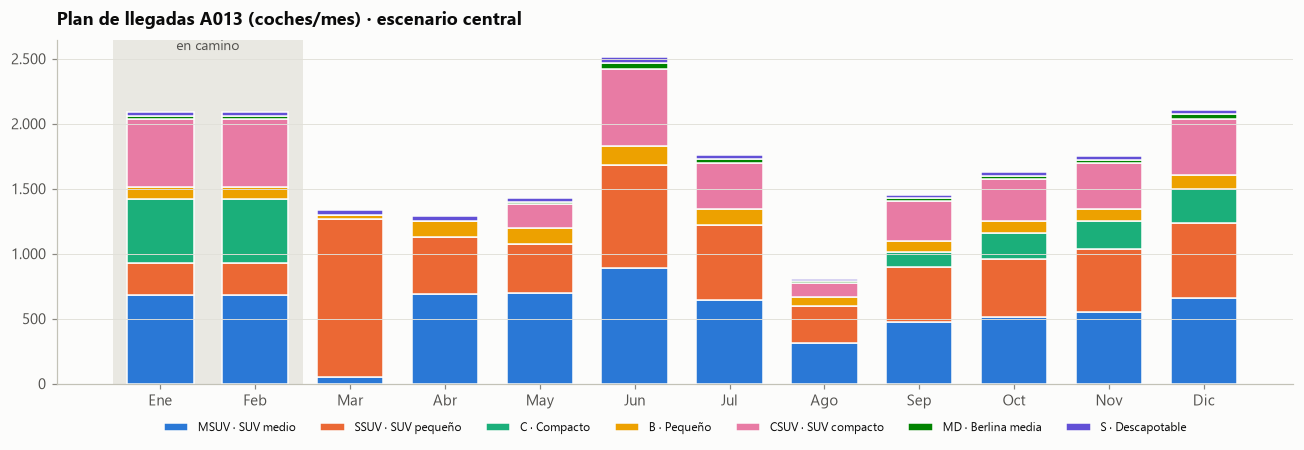

In [9]:
pl = plan.drop(index="TOTAL A013").drop(columns="TOTAL")
fig, ax = plt.subplots(figsize=(12, 4.2))
abajo = np.zeros(12)
for s in SEGMENTOS:
    ax.bar(range(12), pl[s], bottom=abajo, color=COLORES[s], width=0.7, label=f"{s} · {NOMBRES[s]}",
           edgecolor="#fcfcfb", linewidth=1)
    abajo += pl[s].to_numpy()
ax.axvspan(-0.5, 1.5, color=BANDA, lw=0, zorder=0)
ax.text(0.5, abajo.max() * 1.02, "en camino", ha="center", fontsize=9, color=TINTA_2)
ax.set_xticks(range(12), NOMBRES_MES)
eje_miles(ax)
ax.set_title("Plan de llegadas A013 (coches/mes) · escenario central")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncols=7, fontsize=8)
fig.tight_layout()
guardar(fig, "21_plan_llegadas")

**Resultados.**
- **Marzo:** el SUV medio cae a ≈60 coches (viene mucho en camino) y el **SUV pequeño se dispara** (≈1.200) para rellenar una red vacía.
- **Compacto: 0 coches de marzo a agosto.** Tiene stock de sobra; solo vuelve a pedirse en septiembre.
- **SUV compacto:** pausa en marzo–abril (stock del lanzamiento) y luego ritmo normal.
- **Total A013: ≈20.300 llegadas** para una demanda de ≈22.700 → el año usa el stock que sobra y termina con la red más ligera.

> Este plan **no es fijo**: es el punto de partida. Cada mes se revisa (ver §6).

## 6. Simulación: la Tabla 5

Simulamos **1.000 años** por escenario. En cada año la demanda real de cada mes es
```
demanda real = demanda esperada del escenario × e^(sesgo + ruido)
```
- **sesgo** ~ Normal(0; 0,16): igual todo el año (como el error de cuota del SUV medio en A012). **La mitad de su varianza es común a los 7 segmentos** (un mal año lo es para todos) y la otra mitad, propia de cada uno.
- **ruido** ~ Normal(0; σ del segmento): distinto cada mes.

El plan siempre parte de la **previsión central** y se corrige mes a mes. Semilla fija (13) → resultados reproducibles.

In [10]:
res = simular(prev, econ, zs, sigmas, SIGMA_SESGO, stock0, en_camino, R=1000, semilla=13)

t5 = tabla5(res)
fmt = {i: es for i in t5.index}
fmt["Stock medio en la red (meses de venta)"] = lambda x: es(x, 1)
def formatear(tabla):
    out = tabla.copy().astype(object)
    for i in tabla.index:
        f = fmt.get(i, es)
        out.loc[i] = [millones(v) if "(€" in i else f(v) for v in tabla.loc[i]]
    return out
formatear(t5).style.set_caption("TABLA 5 · Total Kaido A013 (media de 1.000 años simulados)")

,Pesimista,Central,Optimista
Coches vendidos (unidades),18.878,22.613,27.678
Coches fabricados / llegadas (unidades),16.617,19.379,22.804
Stock medio en la red (coches),2.132,2.023,1.757
Stock medio en la red (meses de venta),"1,4","1,1","0,8"
Coches con más de 90 días a fin de año,58,39,7
Coste del stock para la marca (€),"1,5 M€","1,4 M€","1,2 M€"
Ventas perdidas (coches),1.392,155,291
Ventas perdidas (€ de CVP),"0,9 M€","0,0 M€","0,1 M€"
Transfers (coches),270,1.333,2.854
Transfers (€ de coste),"0,3 M€","1,5 M€","3,5 M€"


In [11]:
p10, p90 = tabla5(res, estadistico="p10"), tabla5(res, estadistico="p90")
claves = ["Coches vendidos (unidades)", "Ventas perdidas (coches)", "Transfers (coches)", "Margen de la marca, CVP (€)"]
rango = pd.DataFrame({e: [f"{millones(p10.loc[k, e]) if '€' in k else es(p10.loc[k, e])} – "
                          f"{millones(p90.loc[k, e]) if '€' in k else es(p90.loc[k, e])}" for k in claves]
                      for e in ORDEN_ESC}, index=claves)
rango.style.set_caption("Rango probable (del 10 % peor al 10 % mejor de los años simulados)")

,Pesimista,Central,Optimista
Coches vendidos (unidades),16.079 – 21.841,18.958 – 26.433,23.096 – 32.476
Ventas perdidas (coches),704 – 2.219,51 – 276,138 – 469
Transfers (coches),1 – 712,498 – 2.347,1.465 – 4.450
"Margen de la marca, CVP (€)","2,5 M€ – 6,3 M€","68,2 M€ – 96,1 M€","89,6 M€ – 126,5 M€"


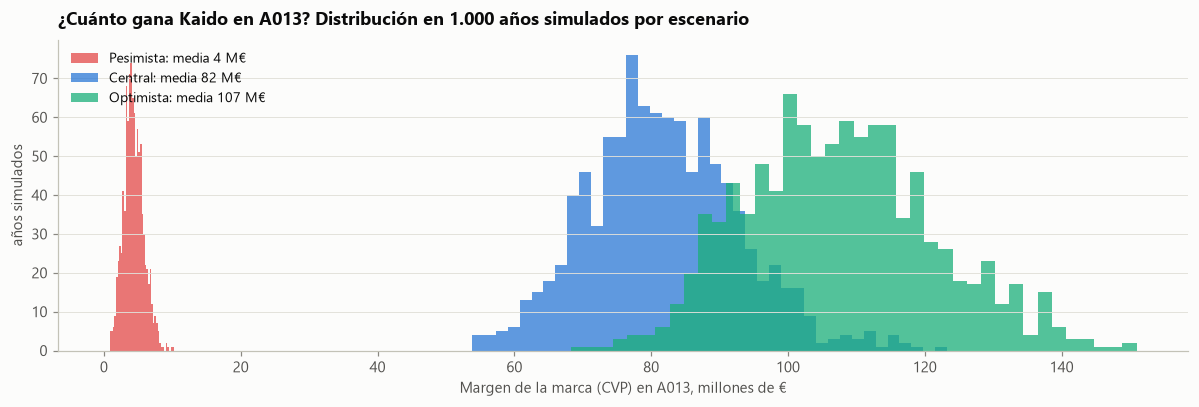

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for e in ORDEN_ESC:
    cvp = sum(res[e][s]["cvp"] for s in SEGMENTOS) / 1e6
    ax.hist(cvp, bins=40, color=COLOR_ESC[e], alpha=0.75, label=f"{e}: media {es(cvp.mean(), 0)} M€")
ax.set_xlabel("Margen de la marca (CVP) en A013, millones de €")
ax.set_ylabel("años simulados")
ax.set_title("¿Cuánto gana Kaido en A013? Distribución en 1.000 años simulados por escenario")
ax.legend(loc="upper left")
fig.tight_layout()
guardar(fig, "22_distribucion_cvp")

**Resultados.**
- **Central: ≈ 82 M€ de CVP** vendiendo ≈22.600 coches, con **≈1,1 meses de stock** y casi **ningún coche de más de 90 días** a fin de año (en diciembre de A012 eran el 35 %).
- **Optimista: ≈ 107 M€.** Se vende más de lo planificado y se cubre con **≈2.900 transfers** (3,5 M€). Compensa de sobra: cada transfer deja dinero.
- **Pesimista: ≈ 4 M€.** El margen **casi desaparece**, y la causa no es el plan: es la **prima de CO₂** (entre 1.900 y 4.500 € por coche). Con ella varios segmentos pierden dinero por coche vendido y los transfers dejan de compensar → ≈1.400 ventas perdidas.

**El central y el optimista se solapan** (un buen año central se parece a un optimista), pero **el pesimista queda muy lejos**: la prima de CO₂ pesa mucho más que la suerte dentro de cada escenario.

**¿Cuánto del golpe del pesimista es la prima de CO₂?** La separamos: lo que pagaría Kaido por la prima en los coches vendidos.

In [13]:
co2 = sum(res["Pesimista"][s]["vendidos"] * econ.loc[s, "prima_co2"] for s in SEGMENTOS).mean()
cvp_p = sum(res["Pesimista"][s]["cvp"] for s in SEGMENTOS).mean()
cvp_c = sum(res["Central"][s]["cvp"] for s in SEGMENTOS).mean()
pd.Series({"CVP central": cvp_c, "CVP pesimista": cvp_p, "  de la caída: prima de CO₂": co2,
           "  de la caída: menos ventas, arancel, roturas": cvp_c - cvp_p - co2,
           "Pesimista sin la prima de CO₂ (aprox.)": cvp_p + co2}).map(millones).to_frame("M€")

,M€
CVP central,"81,8 M€"
CVP pesimista,"4,3 M€"
de la caída: prima de CO₂,"55,5 M€"
"de la caída: menos ventas, arancel, roturas","21,9 M€"
Pesimista sin la prima de CO₂ (aprox.),"59,9 M€"


**Resultados.** de los ≈78 M€ que se pierden del central al pesimista, **≈55 M€ son la prima de CO₂** y ≈22 M€ el resto (menos mercado, retraso del lanzamiento, arancel, la rotura de junio). Sin la prima, el pesimista seguiría dejando ≈60 M€. **La decisión de la matriz sobre la prima pesa más del doble que todo lo demás junto.**

In [14]:
filas = {}
for s in SEGMENTOS:
    filas[f"{s} · {NOMBRES[s]}"] = {
        **{f"Vendidos · {e}": res[e][s]["vendidos"].mean() for e in ORDEN_ESC},
        **{f"CVP M€ · {e}": res[e][s]["cvp"].mean() / 1e6 for e in ORDEN_ESC},
        "Meses de stock · central": res["Central"][s]["meses_venta"].mean(),
    }
seg = pd.DataFrame(filas).T
seg.style.format(es).format(lambda x: es(x, 1), subset=[c for c in seg.columns if "M€" in c or "Meses" in c]) \
   .set_caption("Resultados por segmento (media de 1.000 años)")

,Vendidos · Pesimista,Vendidos · Central,Vendidos · Optimista,CVP M€ · Pesimista,CVP M€ · Central,CVP M€ · Optimista,Meses de stock · central
MSUV · SUV medio,5.659,7.163,8.910,"7,0","41,8","53,8","0,6"
SSUV · SUV pequeño,5.242,6.339,7.949,"-1,7","17,6","23,6","0,4"
C · Compacto,2.444,2.794,3.174,"-3,5","2,7","4,1","3,4"
B · Pequeño,1.008,1.116,1.309,"-2,8","0,1","0,4","0,5"
CSUV · SUV compacto,3.848,4.452,5.489,"4,9","16,3","21,6","1,8"
MD · Berlina media,342,371,418,"0,4","1,4","1,7","1,5"
S · Descapotable,335,378,428,"0,0","1,8","2,2","0,5"


**Resultados por segmento.**
- **SUV medio y SUV pequeño** dan ≈ 3/4 del margen. Son los segmentos que hay que **proteger** (no quedarse sin coches).
- **SUV compacto:** ≈ 16 M€ en su primer año completo. Es el que más crece.
- **Pequeño (B):** gana ≈ 0 en el central y **pierde ≈ 2,8 M€ en el pesimista**. Con la prima de CO₂, cada coche pequeño vendido destruye dinero.
- **Compacto (C):** margen bajo y es el segmento que más stock acumula (≈3 meses). En el pesimista también pierde dinero.

## 7. ¿Cuánto cuesta equivocarse? Sensibilidad del colchón

Pregunta 5: *"compare lo que cuesta quedarse corto con lo que cuesta pasarse"*. Repetimos la simulación multiplicando el colchón de todos los segmentos: **0** (sin colchón), **0,5**, **1** (newsvendor), **2** y **3**. Medimos el margen neto: CVP − coste del stock.

In [15]:
factores = [0, 0.5, 1, 2, 3]
sens = {}
for f in factores:
    zf = zs.copy(); zf["z"] = zs["z"] * f
    r = simular(prev, econ, zf, sigmas, SIGMA_SESGO, stock0, en_camino, R=500, semilla=13)
    for e in ORDEN_ESC:
        neto = sum(r[e][s]["cvp"] - r[e][s]["coste_stock"] for s in SEGMENTOS).mean()
        stock = sum(r[e][s]["stock_medio"] for s in SEGMENTOS).mean()
        corto = sum(r[e][s]["transfers"] + r[e][s]["perdidas"] for s in SEGMENTOS).mean()
        sens[(f, e)] = {"Margen neto (M€)": neto / 1e6, "Stock medio (coches)": stock, "Coches que faltan": corto}
sens = pd.DataFrame(sens).T
sens.index.names = ["× colchón", "escenario"]
sens.unstack("escenario").style.format(lambda x: es(x, 1))

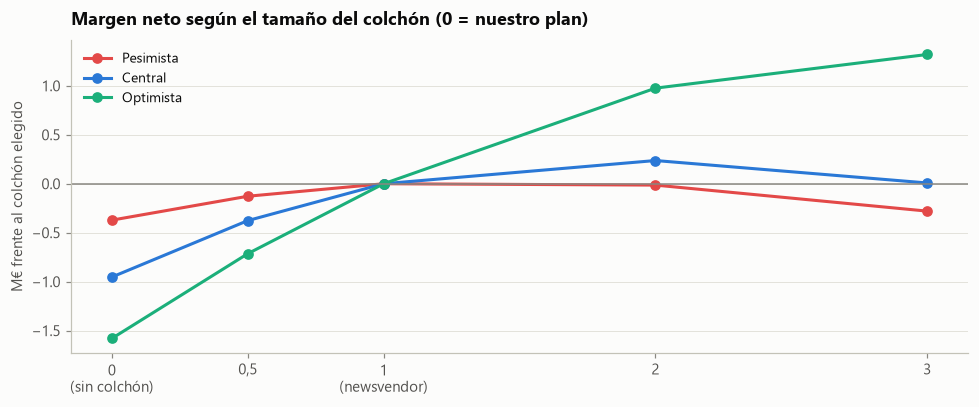

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.8))
base = sens.xs(1, level="× colchón")["Margen neto (M€)"]
for e in ORDEN_ESC:
    y = sens.xs(e, level="escenario")["Margen neto (M€)"] - base[e]
    ax.plot(factores, y, color=COLOR_ESC[e], marker="o", ms=6, label=e)
ax.axhline(0, color=APAGADO, lw=1)
ax.set_xticks(factores, ["0\n(sin colchón)", "0,5", "1\n(newsvendor)", "2", "3"])
ax.set_ylabel("M€ frente al colchón elegido")
ax.set_title("Margen neto según el tamaño del colchón (0 = nuestro plan)")
ax.legend()
fig.tight_layout()
guardar(fig, "23_sensibilidad_colchon")

**Resultados.**
- **Sin colchón** se pierde ≈1 M€ (central) a ≈1,5 M€ (optimista): faltan muchos más coches.
- El margen **sube un poco hasta ×2** y luego se estanca o baja: con más colchón el stock crece (×3 → +50 % de coches parados).
- **El óptimo está algo por encima del newsvendor (×2).** ¿Por qué? La fórmula SS = z·σ·√3 supone errores independientes mes a mes, pero nuestro error tiene **sesgo** (si nos pasamos, nos pasamos todo el año). Es justo lo que avisaba el enunciado: *"si se parecen, el colchón tiene que ser mayor, y la simulación lo mide mejor que la fórmula"*.

**¿Subimos el colchón a ×2?** Ganaríamos ≈0,2 M€ en el central (0,2 %) a cambio de **≈500 coches más parados** en la red. Esos coches cuestan intereses a los **concesionarios** (que no están en el margen de la marca y ya se quejan) y preocupan al **director financiero**. **Mantenemos ×1**: es una decisión consciente de equilibrio entre áreas.

Lo importante: **equivocarse en el colchón cuesta < 1 M€; equivocarse de escenario cuesta ≈ 80 M€** (prima de CO₂). El plan es **robusto**.

## 8. Conclusiones y recomendaciones

### Las respuestas
| Pregunta | Respuesta |
|---|---|
| **3. ¿Y si sale mejor o peor?** | Ventas entre **≈18.900 (pesimista) y ≈27.700 (optimista)**; central ≈22.600. CVP de **≈4 M€ a ≈107 M€**; central ≈82 M€ (rango probable 68–96 M€). Sin la prima de CO₂, el pesimista daría ≈60 M€ |
| **4. ¿Cuántos fabricamos?** | **≈20.300 llegadas** en A013 (plan de §5), con **≈1 mes de stock** en la red. Parar el compacto de marzo a agosto; rellenar el SUV pequeño en marzo |
| **5. ¿Cuánto cuesta equivocarse?** | Quedarse corto cuesta 3–5 veces más que pasarse (salvo en el pequeño). El colchón importa poco; **el escenario (CO₂) importa muchísimo** |

### Recomendaciones al comité
1. **Fabricar para un año de caída**, no para el ritmo de A012: ≈20.300 coches, red con ≈1 mes de stock.
2. **Empujar los SUV** (medio, pequeño y compacto): ≈ 93 % del margen. Proteger su disponibilidad (transfers si falta).
3. **Frenar el pequeño (B):** sin colchón, sin transfers, sin campañas. Con la prima de CO₂ cada coche pierde ≈2.600 €.
4. **Reducir automatriculaciones** (≈11 % de las ventas): no son demanda y alimentan stock viejo.
5. **Vigilar cada mes** y corregir t+3:
   - la **cuota** de Kaido por segmento (la fuente de error nº 1);
   - la **confianza del consumidor** (anticipa el mercado 3 meses);
   - los **coches de más de 90 días** en la red;
   - y la decisión de la matriz sobre la **prima de CO₂**: si la carga, revisar el mix de inmediato.